<div style="background-color:#D4EDDA; color:#155724; padding:12px; border-left:5px solid #28A745; border-radius:5px;">
    <b>Step 1:</b> Load a pretrained embedding model that converts text into 384-dimensional vectors.
</div>

In [1]:
%pip install sentence-transformers matplotlib

   ---------------------------------------- 0.0/780.3 kB ? eta -:--:--
   ---------------------------------------- 780.3/780.3 kB 20.4 MB/s  0:00:00
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 23.6 MB/s  0:00:00
   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ------------------------------------- -- 3.7/3.9 MB 17.1 MB/s eta 0:00:01
   ---------------------------------------- 3.9/3.9 MB 15.4 MB/s  0:00:00
   ---------------------------------------- 0.0/13.6 MB ? eta -:--:--
   --------- ------------------------------ 3.1/13.6 MB 14.5 MB/s eta 0:00:01
   ----------------- ---------------------- 5.8/13.6 MB 13.5 MB/s eta 0:00:01
   ------------------------ --------------- 8.4/13.6 MB 13.1 MB/s eta 0:00:01
   --------------------------------- ------ 11.3/13.6 MB 13.4 MB/s eta 0:00:01
   ---------------------------------------  13.4/13.6 MB 13.2 MB/s eta 0:00:01
   -----------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.0 which is incompatible.


In [2]:
from sentence_transformers import SentenceTransformer, util
import matplotlib.pyplot as plt

model = SentenceTransformer("all-MiniLM-L6-v2")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\heyim\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\heyim\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

<div style="background-color:#D4EDDA; color:#155724; padding:12px; border-left:5px solid #28A745; border-radius:5px;">
    <b>Step 2:</b> Define the user's search query and the available product descriptions.
</div>

In [3]:
query = "I want to sleep comfortably on a long flight"

products = [
    "Memory foam travel neck pillow",
    "Wireless noise-cancelling headphones",
    "Blackout eye mask",
    "Cotton T-shirt designed for a long flight",
    "Long-distance travel backpack"
]

<div style="background-color:#D4EDDA; color:#155724; padding:12px; border-left:5px solid #28A745; border-radius:5px;">
    <b>Step 3:</b> Convert the search query and product descriptions into embeddings.
</div>

In [9]:
query_embedding = model.encode(query)
product_embeddings = model.encode(products)

print("Query embedding shape:", query_embedding.shape)
print("Product embeddings shape:", product_embeddings.shape)

print("\nFirst 10 values of the query embedding:")
print(query_embedding[:10])
print("Entire embedding:\n",query_embedding)

Query embedding shape: (384,)
Product embeddings shape: (5, 384)

First 10 values of the query embedding:
[ 0.10206226  0.02290367 -0.05023586  0.11691229  0.01535426  0.05789677
 -0.02598943 -0.05846351 -0.02266929  0.0480536 ]
Entire embedding:
 [ 1.02062263e-01  2.29036734e-02 -5.02358638e-02  1.16912290e-01
  1.53542645e-02  5.78967705e-02 -2.59894282e-02 -5.84635064e-02
 -2.26692874e-02  4.80535999e-02 -5.52041233e-02  2.81577222e-02
 -5.65909557e-02  5.93732297e-02  5.84193040e-03  1.21121863e-02
  4.96590436e-02  4.83137369e-03  1.94834378e-02  1.41272433e-02
  4.41496111e-02  4.31234576e-02  7.23381117e-02  5.66093959e-02
  3.60641396e-03 -6.80520106e-03  5.23413569e-02 -2.51299031e-02
  2.26704963e-02 -5.62010407e-02 -3.34804021e-02 -1.14745889e-02
 -1.48796979e-02 -1.30097559e-02  2.36818753e-02  3.35389562e-02
  1.20766889e-02 -6.03120476e-02 -2.17699092e-02 -4.47772443e-02
  7.66548514e-02  2.64244783e-03  2.58671325e-02  2.36494914e-02
 -4.03773189e-02  1.02327177e-02 -5.4

<div style="background-color:#D4EDDA; color:#155724; padding:12px; border-left:5px solid #28A745; border-radius:5px;">
    <b>Step 4:</b> Calculate cosine similarity and rank the products from most similar to least similar.
</div>

In [6]:
scores = util.cos_sim(
    query_embedding,
    product_embeddings
)[0].tolist()

results = sorted(
    zip(products, scores),
    key=lambda x: x[1],
    reverse=True
)

for product, score in results:
    print(f"{score:.4f} | {product}")

0.4030 | Cotton T-shirt designed for a long flight
0.3804 | Long-distance travel backpack
0.3188 | Memory foam travel neck pillow
0.1467 | Blackout eye mask
0.1295 | Wireless noise-cancelling headphones


<div style="background-color:#D4EDDA; color:#155724; padding:12px; border-left:5px solid #28A745; border-radius:5px;">
    <b>Step 5:</b> Visualize the similarity scores using a bar chart to identify the most relevant products.
</div>

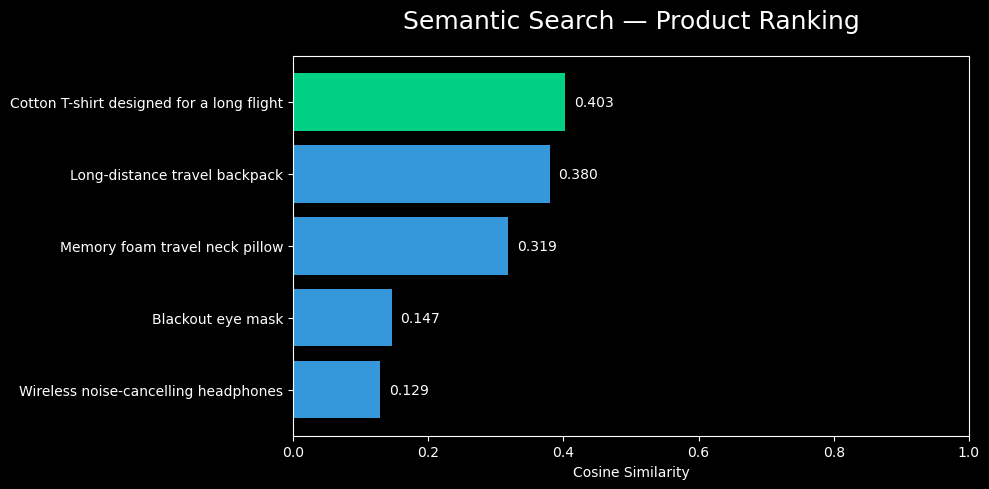

In [7]:
names, similarities = zip(*results)

plt.style.use("dark_background")

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    names,
    similarities,
    color=["#00D084"] + ["#3498DB"] * (len(names) - 1)
)

ax.invert_yaxis()
ax.bar_label(bars, fmt="%.3f", padding=6)

ax.set_xlim(-1 if min(similarities) < 0 else 0, 1)
ax.set_xlabel("Cosine Similarity")
ax.set_title("Semantic Search — Product Ranking",
             fontsize=18, pad=20)

plt.tight_layout()
plt.show()

<div style="background-color:#FFC107; color:#332500; padding:15px; border-left:6px solid #E65100; border-radius:5px;">

<h3>⚠️ Observations and Scope for Improvement</h3>

<p>Although we are searching based on semantic similarity, the neck pillow ranks third instead of first. This demonstrates that embeddings do not always capture the user's intent perfectly.</p>

<ol>
    <li>
        <b>Model Capacity:</b> We deliberately chose all-MiniLM-L6-v2, a lightweight embedding model that can run quickly on a local computer. Its ability to capture complex semantic relationships may be limited.
    </li>
    <br>
    <li>
        <b>Better Embedding Models:</b> We can experiment with more capable embedding models, such as OpenAI's text-embedding-3-large, which may provide better semantic search results.
    </li>
    <br>
    <li>
        <b>Quality of Input Data:</b> Providing detailed product descriptions, including their functionality and use cases, can help the embedding model capture more relevant semantic information.
    </li>
    <br>
    <li>
        <b>Performance Trade-offs:</b> More capable embedding models may improve retrieval quality but can also increase computational requirements, latency, storage requirements and cost.
    </li>
    <br>
    <li>
        <b>Model Evaluation:</b> No embedding model guarantees perfect semantic search results. We must evaluate different models on representative queries and select the one best suited to our specific use case.
    </li>
</ol>

<hr style="border:1px solid #B8860B;">

<b>Key Takeaway:</b> The effectiveness of semantic search depends on the quality of the embedding model, the quality of the input data, and how well the system is evaluated.

</div>